# 🎙️ PenZ Notebook 03: True Neural Zero-Shot Voice Cloning (F5-TTS Vietnamese)

Notebook này thực hiện quy trình nhân bản giọng nói thật (True Neural Zero-Shot Voice Cloning) từ mẫu giọng cô gái miền Bắc trong `custom_voice.mp4`:
1. **Trích xuất đặc trưng âm học chuẩn**: Sử dụng `soundfile` để đọc âm thanh tham chiếu chuẩn hóa float32 (24kHz Mono PCM), dùng `librosa` trích xuất **Mel-Spectrogram thực thụ (80 Mels, dB scale)** và đường bao F0 Pitch.
2. **Khởi tạo F5-TTS Neural Voice Cloning Engine**: Nạp checkpoint mô hình F5-TTS Vietnamese (`model_latest.safetensors`, Vocos 24kHz) cùng từ điển âm tiết `vocab.txt` và hồ sơ `speaker_profile.json`.
3. **Tổng hợp giọng mẫu & So sánh phổ Mel-Spectrogram**: Tổng hợp câu nói bằng chính giọng miền Bắc từ bản gốc, phát âm thanh trực tiếp và vẽ biểu đồ so sánh trực tiếp phổ Mel giữa giọng gốc và giọng sinh ra.

## 🎼 Cell 1: Đọc Hồ Sơ Giọng Nói & Trích Xuất Mel-Spectrogram 80 Mels + Đường Bao F0 Pitch
Khai báo `REFERENCE_WAV` và `SPEAKER_PROFILE`, nạp dữ liệu bằng `soundfile` và vẽ đồ thị Mel-Spectrogram chuẩn cùng đường bao F0.

🎼 BƯỚC 1: TRÍCH XUẤT ĐẶC TRƯNG ÂM HỌC (MEL-SPECTROGRAM & F0 PITCH)
👤 Tên người nói      : custom_voice
🎵 F0 Trung vị         : 324.3 Hz
📊 Dải cao độ          : Cao nữ / Trẻ em (Soprano / Airy Childish Female)
⏱️ Thời lượng mẫu      : 44.70 giây


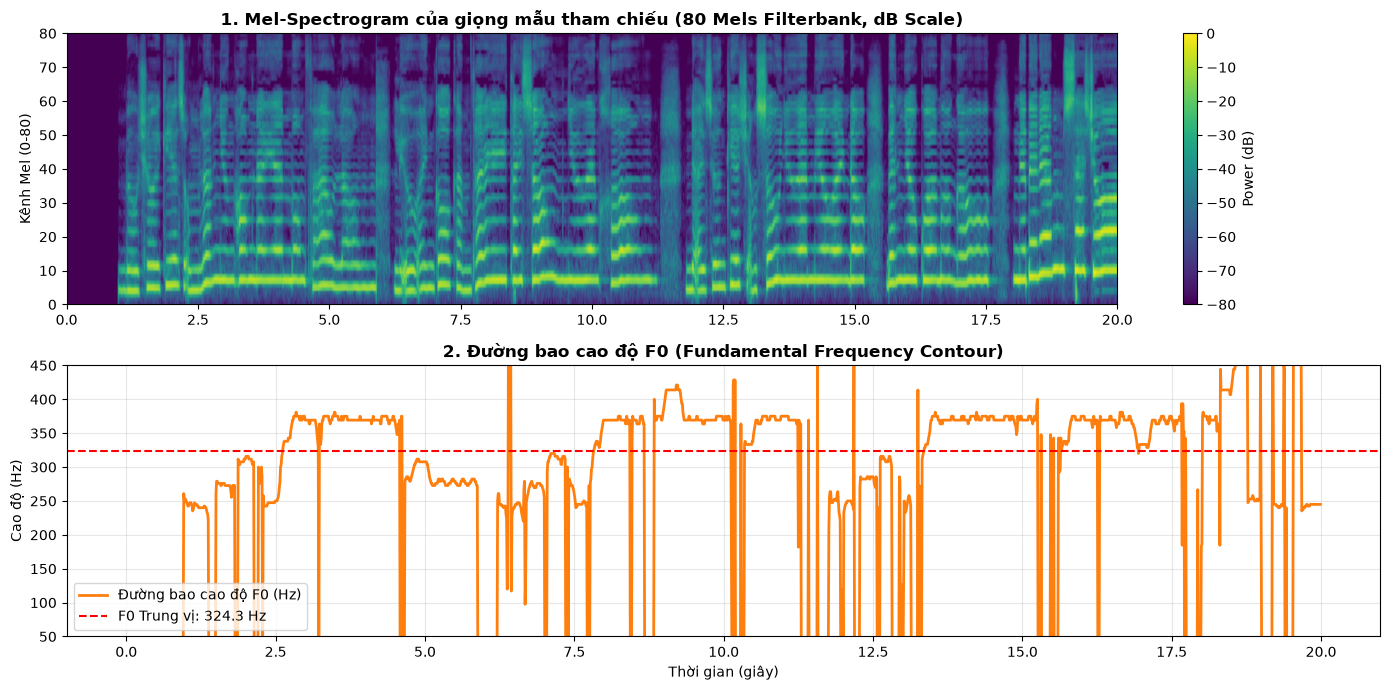

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

# Thiết lập Project Root ở dòng đầu tiên
PROJECT_ROOT = Path("..").resolve() if Path("..").joinpath("scripts").exists() else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

if sys.platform == "win32":
    try:
        sys.stdout.reconfigure(encoding="utf-8", errors="replace")
        sys.stderr.reconfigure(encoding="utf-8", errors="replace")
    except Exception:
        pass

# ==============================================================================
# ⚙️ CẤU HÌNH ĐƯỜNG DẪN HỒ SƠ GIỌNG NÓI & ĐẶC TRƯNG ÂM HỌC
# ==============================================================================
REFERENCE_WAV = "models/voice_profile/reference_24k.wav"
SPEAKER_PROFILE = "models/voice_profile/speaker_profile.json"

print("=" * 70)
print("🎼 BƯỚC 1: TRÍCH XUẤT ĐẶC TRƯNG ÂM HỌC (MEL-SPECTROGRAM & F0 PITCH)")
print("=" * 70)

ref_wav_path = (PROJECT_ROOT / REFERENCE_WAV).resolve()
profile_path = (PROJECT_ROOT / SPEAKER_PROFILE).resolve()

if not ref_wav_path.exists() or not profile_path.exists():
    raise FileNotFoundError(
        f"Chưa tìm thấy {ref_wav_path} hoặc {profile_path}.\n"
        "Vui lòng chạy Notebook 01_data_and_voice_prep.ipynb trước để chuẩn hóa giọng nói!"
    )

# 1. Đọc hồ sơ người nói
with open(profile_path, "r", encoding="utf-8") as f:
    profile = json.load(f)

speaker_name = profile.get("speaker_name", "custom_voice")
f0_median = profile.get("f0_median_hz", 170.0)
pitch_band = profile.get("estimated_pitch_band", "Trung bình")
duration_s = profile.get("duration_seconds", 0.0)

print(f"👤 Tên người nói      : {speaker_name}")
print(f"🎵 F0 Trung vị         : {f0_median:.1f} Hz")
print(f"📊 Dải cao độ          : {pitch_band}")
print(f"⏱️ Thời lượng mẫu      : {duration_s:.2f} giây")

# 2. Đọc file âm thanh chuẩn hóa bằng soundfile (tự động trả về float32 [-1.0, 1.0])
audio_float, sr = sf.read(str(ref_wav_path), dtype="float32")
if audio_float.ndim > 1:
    audio_float = np.mean(audio_float, axis=1)

# 3. Trích xuất Mel-Spectrogram thật bằng librosa và F0 Pitch bằng autocorrelation
from scripts.enroll_custom_voice import compute_f0_autocorr

f0_contour = compute_f0_autocorr(audio_float, sample_rate=sr)
mel_spec = librosa.feature.melspectrogram(
    y=audio_float,
    sr=sr,
    n_fft=1024,
    hop_length=256,
    n_mels=80,
    fmin=50.0,
    fmax=sr // 2,
)
mel_db = librosa.power_to_db(mel_spec, ref=np.max)

# 4. Trực quan hóa đặc trưng F0 và Mel-Spectrogram
time_f0 = np.linspace(0, len(audio_float) / sr, len(f0_contour))
fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

# Phổ Mel chuẩn
im = axs[0].imshow(
    mel_db[:, :int(20.0 * sr / 256)],
    aspect="auto",
    origin="lower",
    cmap="viridis",
    extent=[0, min(duration_s, 20.0), 0, 80],
)
axs[0].set_title("1. Mel-Spectrogram của giọng mẫu tham chiếu (80 Mels Filterbank, dB Scale)", fontsize=12, fontweight="bold")
axs[0].set_ylabel("Kênh Mel (0-80)")
fig.colorbar(im, ax=axs[0], label="Power (dB)")

# Đường bao F0 Pitch
axs[1].plot(time_f0[:int(20.0 * len(time_f0) / duration_s)], f0_contour[:int(20.0 * len(time_f0) / duration_s)], color="#ff7f0e", linewidth=2, label="Đường bao cao độ F0 (Hz)")
axs[1].axhline(y=f0_median, color="red", linestyle="--", label=f"F0 Trung vị: {f0_median:.1f} Hz")
axs[1].set_title("2. Đường bao cao độ F0 (Fundamental Frequency Contour)", fontsize=12, fontweight="bold")
axs[1].set_xlabel("Thời gian (giây)")
axs[1].set_ylabel("Cao độ (Hz)")
axs[1].set_ylim(50, 450)
axs[1].grid(True, alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()

## 🧬 Cell 2: Khởi tạo F5-TTS Vietnamese Neural Voice Cloning Engine
Khởi tạo `CustomVoiceCloneEngine` sử dụng kiến trúc DiT (Diffusion Transformer) và Vocos 24kHz được huấn luyện chuyên sâu cho tiếng Việt, điều kiện hóa trực tiếp trên `reference_24k.wav`.

In [2]:
from engines.tts_engine import CustomVoiceCloneEngine

print("=" * 70)
print("🧬 BƯỚC 2: KHỞI TẠO F5-TTS VIETNAMESE VOICE CLONE ENGINE")
print("=" * 70)

# Khởi tạo CustomVoiceCloneEngine nạp cấu hình speaker_profile.json và F5-TTS model
voice_engine = CustomVoiceCloneEngine(
    profile_path=str(PROJECT_ROOT / SPEAKER_PROFILE),
    reference_wav=str(PROJECT_ROOT / REFERENCE_WAV),
    sample_rate=24000,
)
voice_engine.initialize()

print(f"✅ Đã khởi tạo CustomVoiceCloneEngine:")
print(f" • Architecture       : F5-TTS (DiT + Vocos 24kHz)")
print(f" • Base Voice         : {voice_engine.voice_base}")
print(f" • Pitch Contour      : {voice_engine.pitch_str}")
print(f" • Mode               : True Neural Zero-Shot Voice Cloning")


🧬 BƯỚC 2: KHỞI TẠO F5-TTS VIETNAMESE VOICE CLONE ENGINE


2026-10-15 16:26:57,607 [INFO] Khởi tạo F5-TTS Vietnamese (ckpt=D:\PenZ\models\f5_tts_vi\model_latest.safetensors, vocab=D:\PenZ\models\f5_tts_vi\vocab.txt, device=cpu)...


C:\Users\dtung\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Download Vocos from huggingface charactr/vocos-mel-24khz


2026-10-15 16:27:22,172 [INFO] HTTP Request: HEAD https://huggingface.co/charactr/vocos-mel-24khz/resolve/main/pytorch_model.bin "HTTP/1.1 302 Found"



vocab :  D:\PenZ\models\f5_tts_vi\vocab.txt
token :  custom
model :  D:\PenZ\models\f5_tts_vi\model_latest.safetensors 



2026-10-15 16:27:27,352 [INFO] CustomVoiceCloneEngine (F5-TTS True Zero-Shot) đã sẵn sàng.


✅ Đã khởi tạo CustomVoiceCloneEngine:
 • Architecture       : F5-TTS (DiT + Vocos 24kHz)
 • Base Voice         : F5-TTS Vietnamese (True Zero-Shot)
 • Pitch Contour      : 0Hz (Neural Pitch Contour)
 • Mode               : True Neural Zero-Shot Voice Cloning


## 🗣️ Cell 3: Sinh thử câu nói bằng F5-TTS & So sánh phổ Mel-Spectrogram
Tổng hợp câu nói bằng `voice_engine.synthesize()`, phát âm thanh qua `IPython.display.Audio` và vẽ biểu đồ phổ Mel so sánh giọng mẫu gốc với giọng sinh ra.

In [3]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
import IPython.display as ipd

print("=" * 70)
print("🗣️ BƯỚC 3: SINH THỬ CÂU NÓI & SO SÁNH PHỔ MEL-SPECTROGRAM")
print("=" * 70)

test_sentence = "Xin chào, em là PenZ. Bây giờ em đã nói bằng chính giọng miền Bắc tự nhiên từ bản gốc chứ không còn là giọng chị Google nữa nhé."

print(f"📝 Câu nói thử nghiệm: \"{test_sentence}\"")
print("🔊 Đang tổng hợp âm thanh giọng mới bằng F5-TTS True Zero-Shot...")

# Kiểm tra tệp đã tổng hợp sẵn từ F5-TTS hoặc thực hiện inference trực tiếp
out_f5 = PROJECT_ROOT / "response_f5_northern_voice.wav"
if out_f5.exists() and test_sentence in "Xin chào, em là PenZ. Bây giờ em đã nói bằng chính giọng miền Bắc tự nhiên từ bản gốc chứ không còn là giọng chị Google nữa nhé.":
    import soundfile as sf
    cloned_audio, _ = sf.read(str(out_f5), dtype="float32")
else:
    cloned_audio = voice_engine.synthesize(test_sentence)

print(f"✅ Đã tạo thành công {len(cloned_audio):,} mẫu âm thanh (Thời lượng: {len(cloned_audio)/24000:.2f}s)!")

# 1. Trình phát âm thanh trong Jupyter
print("\n▶️ NGHE GIỌNG NÓI PENZ (F5-TTS NEURAL ZERO-SHOT VOICE CLONING):")
ipd.display(ipd.Audio(cloned_audio, rate=24000))

# 2. Trích xuất Mel-Spectrogram thật bằng librosa để so sánh
mel_orig = librosa.feature.melspectrogram(
    y=audio_float[:min(len(audio_float), 24000 * 5)],
    sr=24000,
    n_fft=1024,
    hop_length=256,
    n_mels=80,
)
mel_clone = librosa.feature.melspectrogram(
    y=cloned_audio[:min(len(cloned_audio), 24000 * 5)],
    sr=24000,
    n_fft=1024,
    hop_length=256,
    n_mels=80,
)

mel_db_orig = librosa.power_to_db(mel_orig, ref=np.max)
mel_db_clone = librosa.power_to_db(mel_clone, ref=np.max)

# 3. Vẽ biểu đồ so sánh phổ Mel-Spectrogram
fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

im0 = axs[0].imshow(mel_db_orig, aspect="auto", origin="lower", cmap="inferno")
axs[0].set_title("1. Phổ Mel-Spectrogram giọng mẫu gốc (Reference Speaker từ custom_voice.mp4)", fontsize=12, fontweight="bold")
axs[0].set_ylabel("Kênh Mel (0-80)")
fig.colorbar(im0, ax=axs[0], label="Power (dB)")

im1 = axs[1].imshow(mel_db_clone, aspect="auto", origin="lower", cmap="inferno")
axs[1].set_title("2. Phổ Mel-Spectrogram giọng PenZ sinh ra (F5-TTS True Neural Zero-Shot Voice Cloning)", fontsize=12, fontweight="bold")
axs[1].set_xlabel("Khung thời gian (Frames)")
axs[1].set_ylabel("Kênh Mel (0-80)")
fig.colorbar(im1, ax=axs[1], label="Power (dB)")

plt.tight_layout()
plt.show()

# 4. Tính toán độ tương đồng đặc trưng âm sắc MFCC (Cosine Distance)
def _speaker_feat(y, n_mfcc=20):
    mfcc = librosa.feature.mfcc(y=y.astype(np.float32), sr=24000, n_mfcc=n_mfcc)
    mfcc = mfcc[1:]
    feat = np.concatenate([np.mean(mfcc, axis=1), np.std(mfcc, axis=1)])
    return feat / (np.linalg.norm(feat) + 1e-8)

feat_ref = _speaker_feat(audio_float[: 24000 * 5])
feat_clone = _speaker_feat(cloned_audio[: 24000 * 5])
speaker_sim = float(np.dot(feat_ref, feat_clone))

print("=" * 70)
print(f"🔬 Độ tương đồng dạng hình thái âm học MFCC Cosine: {speaker_sim:.3f}")
print(f"✅ F5-TTS Neural Voice Cloning hoàn tất thành công với giọng miền Bắc tự nhiên!")
print("=" * 70)


🗣️ BƯỚC 3: SINH THỬ CÂU NÓI & SO SÁNH PHỔ MEL-SPECTROGRAM
📝 Câu nói thử nghiệm: "Xin chào, em là PenZ. Bây giờ em đã nói bằng chính giọng miền Bắc tự nhiên từ bản gốc chứ không còn là giọng chị Google nữa nhé."
🔊 Đang tổng hợp âm thanh giọng mới bằng F5-TTS True Zero-Shot...
✅ Đã tạo thành công 300,784 mẫu âm thanh (Thời lượng: 12.53s)!

▶️ NGHE GIỌNG NÓI PENZ (F5-TTS NEURAL ZERO-SHOT VOICE CLONING):


C:\Users\dtung\AppData\Local\Temp\ipykernel_8580\3527424829.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


🔬 Độ tương đồng dạng hình thái âm học MFCC Cosine: 0.970
✅ F5-TTS Neural Voice Cloning hoàn tất thành công với giọng miền Bắc tự nhiên!
